# Data Workflow

This page takes the results of the reaction coordinate scan from the [Diels-Alder chapter](8A_Diels_Alder.ipynb), where the C3–C5 and C4–C6 bonds of *C<sub>s</sub>* cyclohexene were frozen at lengths from 1.45 to 3.00&nbsp;Å and the rest of the molecule was optimized. We will collect the final energy from each of the 32 log files, clean up the data with *pandas*, convert the energies to kJ/mol, plot the energy profile and save the result.

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`. The scan log files are read from the `runs/` folder, where the [Diels-Alder chapter](8A_Diels_Alder.ipynb) wrote them. If you have not run the scan yourself, this notebook uses a copy of the results that comes with the book in the `data/` folder.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). This page only reads log files; it does not run GAMESS.
from pathlib import Path
import gamess_tools as gt

RUNS = Path("runs")         # where the scan log files were written
DATA = Path("data")         # results and plot style that come with the book

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## Collecting the Results

In the original version of this book the last `NSERCH` line of each log file was pulled out with a small *bash* script, `extract.sh`, and saved as `results.txt`:

```bash
for name in Cyclohexene_Cs_scan.inp_SCAN*.log; do
    grep -H "NSERCH" "$name" | grep "GRAD" | tail -n 1
done
```

The cell below does the same thing in *Python*. For each log file it finds the lines that contain `NSERCH` and `GRAD` (that is what `gt.grep()` does), keeps the last one, and writes it after the name of the file. If there are no scan logs in `runs/`, it falls back to the copy in `data/`.

In [2]:
logs = sorted(RUNS.glob("Cyclohexene_Cs_SCAN_*.log"))

if logs:
    results_file = RUNS / "cyclohexene_scan_results.txt"
    lines = []
    for log in logs:
        last = [line for line in gt.grep("NSERCH", log) if "GRAD" in line][-1]
        lines.append(f"{log.stem} {last.strip()}")
    results_file.write_text("\n".join(lines) + "\n")
    print(f"read {len(logs)} log files from {RUNS}/")
else:
    results_file = DATA / "cyclohexene_scan_results.txt"
    print(f"no scan logs found in {RUNS}/, using the copy in {DATA}/")

print(results_file.read_text())

read 32 log files from runs/
Cyclohexene_Cs_SCAN_1.45 NSERCH:  11  E=     -232.9995497493  GRAD. MAX=  0.0000706  R.M.S.=  0.0000276
Cyclohexene_Cs_SCAN_1.50 NSERCH:  10  E=     -233.0074050634  GRAD. MAX=  0.0000652  R.M.S.=  0.0000285
Cyclohexene_Cs_SCAN_1.55 NSERCH:   5  E=     -233.0091271727  GRAD. MAX=  0.0000742  R.M.S.=  0.0000284
Cyclohexene_Cs_SCAN_1.60 NSERCH:  11  E=     -233.0061114211  GRAD. MAX=  0.0000633  R.M.S.=  0.0000303
Cyclohexene_Cs_SCAN_1.65 NSERCH:  19  E=     -232.9994858977  GRAD. MAX=  0.0000841  R.M.S.=  0.0000299
Cyclohexene_Cs_SCAN_1.70 NSERCH:  20  E=     -232.9901643852  GRAD. MAX=  0.0000448  R.M.S.=  0.0000193
Cyclohexene_Cs_SCAN_1.75 NSERCH:  20  E=     -232.9789005901  GRAD. MAX=  0.0000484  R.M.S.=  0.0000219
Cyclohexene_Cs_SCAN_1.80 NSERCH:  20  E=     -232.9663220865  GRAD. MAX=  0.0000507  R.M.S.=  0.0000230
Cyclohexene_Cs_SCAN_1.85 NSERCH:  20  E=     -232.9529605653  GRAD. MAX=  0.0000630  R.M.S.=  0.0000252
Cyclohexene_Cs_SCAN_1.90 NSERCH:  2

If you open the results file in a text editor you will see thirty-two lines of data, one line for each file.

Within the file name is the length of the two frozen C–C bonds in Å. The step number for the last energy calculation, `NSERCH`, is next. The energy follows that and the value is in units of hartree/molecule. We will want to convert that to kJ/mol. Then we have the largest component of the energy gradient for the last structure of the optimization (`GRAD. MAX`). It should be less than 0.0001 for the calculation to stop. We could have set this lower or higher. The last value recorded in each line is the RMS (root mean square) of the gradient.

## Import Raw Data

We could edit the data in a text editor but we will do everything using the data analysis tools of *Python* and *pandas*. First we will import the data as a dataframe using *pandas*. The data file must be in the same directory as this workbook, or you must specify the file path. Don't worry, *Python* will scream at you if you make a mistake and you will be able to fix any problems.

We will use the `pandas.read_csv()` function to read the file and create a dataframe object. The `header = None` setting prevents the first line from being used to label the columns. The `sep = r"\s+|_"` establishes that one or more spaces separates columns and also the `_` character separates columns. The `engine = "python"` means to use the *Python* engine rather than the default C engine. The C engine is much faster, but it is not compatible with the way I am using the `sep` parameter. How do I know this? I got an error message that told me what to do.

In [3]:
import pandas as pd

df = pd.read_csv(results_file, header = None, sep = r"\s+|_", engine = "python")

display(df.head())

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,Cyclohexene,Cs,SCAN,1.45,NSERCH:,11,E=,-232.999550,GRAD.,MAX=,0.000071,R.M.S.=,0.000028
1,Cyclohexene,Cs,SCAN,1.50,NSERCH:,10,E=,-233.007405,GRAD.,MAX=,0.000065,R.M.S.=,0.000029
2,Cyclohexene,Cs,SCAN,1.55,NSERCH:,5,E=,-233.009127,GRAD.,MAX=,0.000074,R.M.S.=,0.000028
3,Cyclohexene,Cs,SCAN,1.60,NSERCH:,11,E=,-233.006111,GRAD.,MAX=,0.000063,R.M.S.=,0.000030
4,Cyclohexene,Cs,SCAN,1.65,NSERCH:,19,E=,-232.999486,GRAD.,MAX=,0.000084,R.M.S.=,0.000030


## Cleaning the Data

Data cleaning is half the work in data analysis. We need to drop empty records and malformed records (each line could be considered a record in this case). We will need to drop any fields that we do not need (the columns in each record are the fields). Inspecting the dataframe shows me that I only need columns 3, 5, 7 and 10. We will rename the columns for what they represent. Inspect the original dataframe above to see where I got my labels from.

In the code below I create a new dataframe by selecting the four chosen columns out of the previous dataframe. Then I renamed the column headers from numbers to labels so I don't forget what they are.

In [4]:
coord = df[[3, 5, 7, 10]]
coord = coord.rename({3:'Length', 5:'NSERCH', 7:'Energy', 10:'GRAD'}, axis='columns')
display(coord.head())

,Length,NSERCH,Energy,GRAD
0,1.45,11,-232.999550,0.000071
1,1.50,10,-233.007405,0.000065
2,1.55,5,-233.009127,0.000074
3,1.60,11,-233.006111,0.000063
4,1.65,19,-232.999486,0.000084


## Processing the Data

We now have a cleaned up data set. We could have done all of this in *Excel* by importing the text file, setting column breaks manually, deleting unwanted columns manually and then typing in names for the columns. *Python* and *pandas* may seem like a bit of work but it is not any more than you would do setting up the data in *Excel*.

We know that a hartree is 2625.5&nbsp;kJ/mol. So we can convert the energy to a more familiar unit. Then we should set our lowest energy structure as the zero reference and subtract that value from all the energies to establish a relative scale.

In [5]:
import numpy as np

lowest_energy = np.min(coord["Energy"])
coord["DeltaE"] = (coord["Energy"] - lowest_energy) * HARTREE_TO_KJMOL
display(coord)

,Length,NSERCH,Energy,GRAD,DeltaE
0,1.45,11,-232.999550,0.000071,25.145525
1,1.50,10,-233.007405,0.000065,4.521398
2,1.55,5,-233.009127,0.000074,0.000000
3,1.60,11,-233.006111,0.000063,7.917856
4,1.65,19,-232.999486,0.000084,25.313168
5,1.70,20,-232.990164,0.000045,49.786799
6,1.75,20,-232.978901,0.000048,79.359893
7,1.80,20,-232.966322,0.000051,112.384754
8,1.85,20,-232.952961,0.000063,147.465428
9,1.90,21,-232.939279,0.000038,183.387205


## Plotting the Profile

Now we have a set of data that we can plot. Let us visualize the profile using the *Matplotlib* library.

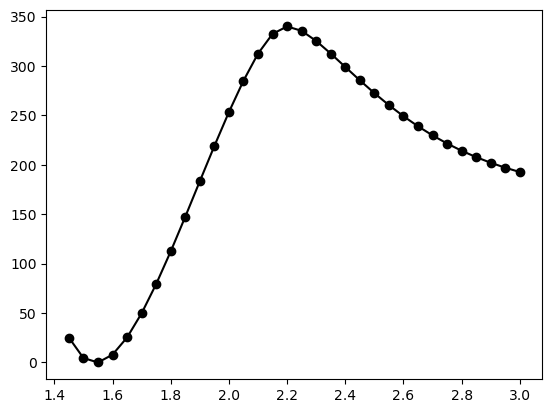

In [6]:
import matplotlib.pyplot as plt

x = coord["Length"]
y = coord["DeltaE"]

plt.plot(x, y, "ko-")
plt.show()

## Publication Quality

We can be more stylish. I will use the stylesheet that I edited to my preference, `S2_classic2.mplstyle`. It comes with the book in the `data/` folder.

Different journals have different standards for plots. Just follow their instructions. Many will have stylesheets available for your word processor, for $\LaTeX$ and even for *MacMolPlt*. Use the `savefig()` method of the `fig` object to save the plot as a file. The `.pdf` extension will tell it to save in PDF format.

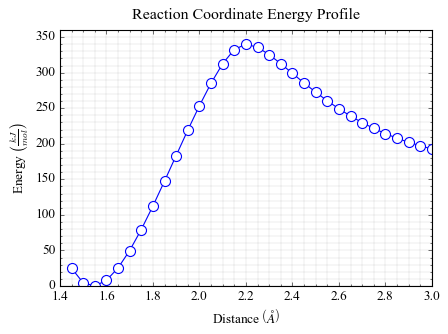

In [7]:
x = coord["Length"]
y = coord["DeltaE"]

plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))

ax.plot(x, y, "o-")

ax.set(title="Reaction Coordinate Energy Profile",
          ylabel=r"Energy $\left(\frac{kJ}{mol}\right)$",
          xlabel=r"Distance $\left(\AA\right)$",
          xlim=[1.4, 3.0],
          ylim=[0, 360]
      )

#fig.savefig(RUNS / "plot.pdf")
plt.show()

The plot above is a "connect-the-dots" style plot. There are many data points and it looks fine. We do not have an exact function to which to fit the data but we could apply the infamous "cubic spline." We will use the `CubicSpline` function available from the `scipy.interpolate` library ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)) to generate a function that represents the curve fit. We will then feed an *x*-axis of many data points into that function to create an *x*,*y* data set that represents that curve fit as a smooth line. The smooth line only covers the range of our data (1.45 to 3.00&nbsp;Å): a spline should not be trusted outside the points it was made from.

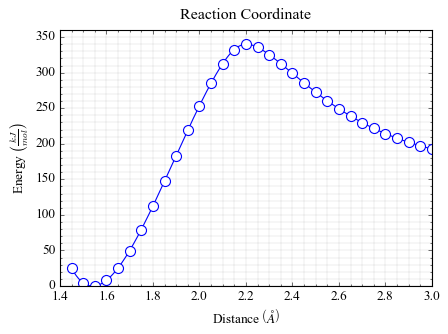

In [8]:
from scipy.interpolate import CubicSpline

plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))

cs = CubicSpline(coord["Length"], coord["DeltaE"])
x = np.linspace(1.45, 3.00, 300)
y = cs(x)
ax.plot(x, y, "-")

x = coord["Length"]
y = coord["DeltaE"]
ax.plot(x, y, "o")

ax.set(title="Reaction Coordinate",
          ylabel=r"Energy $\left(\frac{kJ}{mol}\right)$",
          xlabel=r"Distance $\left(\AA\right)$",
          xlim=[1.4, 3.0],
          ylim=[0, 360]
      )

#fig.savefig(RUNS / "plot.pdf")
plt.show()

The spline also gives us a quick estimate of where the top of the barrier is. This is the structure we will want to start from when we look for the transition state.

In [9]:
x = np.linspace(1.45, 3.00, 3101)          # every 0.0005 Å
top = x[np.argmax(cs(x))]
print(f"highest point of the spline: {top:.3f} Å, {cs(top):.1f} kJ/mol above cyclohexene")
print(f"highest scan point:          {coord.loc[coord['DeltaE'].idxmax(), 'Length']:.2f} Å")

highest point of the spline: 2.203 Å, 340.1 kJ/mol above cyclohexene
highest scan point:          2.20 Å


## Saving the Data

We have imported, cleaned and processed the data. Maybe we should save our work so we can use this data set directly and easily next time. The dataframe object contains methods to do this. We will use the `pandas.DataFrame.to_csv()` method ([documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html)) to save the dataframe object as a CSV text file in the `runs/` folder.

In [10]:
coord.to_csv(RUNS / "coord_profile.csv")

The cyclohexene energy profile data is now saved in a file named `coord_profile.csv`. Below, the file is printed so you can see what CSV format looks like. Next time, `pd.read_csv(RUNS / "coord_profile.csv", index_col=0)` will give us the clean dataframe in one step.

In [11]:
print((RUNS / "coord_profile.csv").read_text())

,Length,NSERCH,Energy,GRAD,DeltaE
0,1.45,11,-232.9995497493,7.06e-05,25.14552513670847
1,1.5,10,-233.0074050634,6.52e-05,4.521397967162088
2,1.55,5,-233.0091271727,7.42e-05,0.0
3,1.6,11,-233.0061114211,6.33e-05,7.917855825808175
4,1.65,19,-232.9994858977,8.41e-05,25.313167512518376
5,1.7,20,-232.9901643852,4.48e-05,49.78679858129087
6,1.75,20,-232.9789005901,4.84e-05,79.35989261628396
7,1.8,20,-232.9663220865,5.07e-05,112.38475381807554
8,1.85,20,-232.9529605653,6.3e-05,147.46542772870413
9,1.9,21,-232.9392786848,3.77e-05,183.38720498145898
10,1.95,21,-232.9256963349,5.57e-05,219.04766464388584
11,2.0,21,-232.912628428,7.97e-05,253.35745420984964
12,2.05,21,-232.9005442078,8.07e-05,285.0845743449362
13,2.1,21,-232.8900966067,9.69e-05,312.51475103297946
14,2.15,21,-232.8824624035,6.99e-05,332.5583515346129
15,2.2,22,-232.8796092131,4.35e-05,340.0494029298216
16,2.25,22,-232.8812781492,7.89e-05,335.667611199263
17,2.3,23,-232.8851867409,4.5e-05,325.4056036909219
18,2.35,24,-232.890039599

## AI Statement

This page was converted from the original notebook `8_Reaction_Coord_Scan_Data.ipynb` with the help of Claude (Anthropic), following the author's instructions.

- **Original text and code kept (about 80 %).** The explanations of importing, cleaning, processing, plotting, the spline fit and saving are the author's, as are the *pandas* and *Matplotlib* code and the plot stylesheet. Small edits: typos fixed, "nineteen lines" and "torsion angle" corrected to thirty-two lines and bond length, the column numbers updated for the new file names, the hartree conversion set to 2625.5&nbsp;kJ/mol to match the rest of the book, and the spline now drawn only over the range of the data (the original evaluated it from 1.4&nbsp;Å in 0.1&nbsp;Å steps).
- **Written by AI.** The introduction, the settings cell, the "Collecting the Results" section (a *Python* version of `extract.sh` that reads the log files directly), the barrier-top estimate from the spline, and the cell that prints the saved CSV file.
- **Changed workflow.** The data come from your own scan in `runs/` instead of a `results.txt` file downloaded from *GitHub*; the stylesheet is read from the local `data/` folder. The numbers are from a new run of *GAMESS* 2023 R2 and differ slightly from the original book.